In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Set visual style
%matplotlib inline
sns.set_theme(style="whitegrid")

In [2]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
gender_sub_df = pd.read_csv('gender_submission.csv')

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape: {test_df.shape}")
print(f"Gender Submission Shape: {gender_sub_df.shape}")

Train Shape: (891, 12)
Test Shape: (418, 11)
Gender Submission Shape: (418, 2)


In [3]:
# Compute imputation values strictly from training dataset to prevent data leakage
age_median = train_df['Age'].median()
fare_median = train_df['Fare'].median()
embarked_mode = train_df['Embarked'].mode()[0]

def preprocess_titanic(df, age_med, fare_med, emb_mode):
    df_clean = df.copy()
    
    # Impute missing values using training set statistics
    df_clean['Age'] = df_clean['Age'].fillna(age_med)
    df_clean['Fare'] = df_clean['Fare'].fillna(fare_med)
    df_clean['Embarked'] = df_clean['Embarked'].fillna(emb_mode)
    
    # Binary encoding
    df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})
    
    # One-Hot Encoding
    df_clean = pd.get_dummies(df_clean, columns=['Embarked'], drop_first=True)
    
    # Feature Engineering: FamilySize
    df_clean['FamilySize'] = df_clean['SibSp'] + df_clean['Parch'] + 1
    
    # Drop unnecessary columns
    drop_cols = ['PassengerId', 'Name', 'Ticket', 'Cabin']
    df_clean = df_clean.drop(columns=[col for col in drop_cols if col in df_clean.columns])
    
    return df_clean

# Preprocess Train and Test independently
train_processed = preprocess_titanic(train_df, age_median, fare_median, embarked_mode)
test_processed = preprocess_titanic(test_df, age_median, fare_median, embarked_mode)

X_train_full = train_processed.drop(columns=['Survived'])
y_train_full = train_processed['Survived']

# Align test set columns with training set columns (prevents dummy column mismatch)
X_test_final = test_processed.reindex(columns=X_train_full.columns, fill_value=0)
y_test_final = gender_sub_df['Survived']

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full
)

In [5]:
# Train model on 80% train split for validation
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
model.fit(X_train, y_train)

# Predict on validation split
y_val_pred = model.predict(X_val)
y_val_probs = model.predict_proba(X_val)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_val, y_val_pred).ravel()

acc = accuracy_score(y_val, y_val_pred)
prec = precision_score(y_val, y_val_pred)
rec = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
specificity = tn / (tn + fp)
auc = roc_auc_score(y_val, y_val_probs)
loss = log_loss(y_val, y_val_probs)

print("\n" + "=" * 50)
print("         MODEL EVALUATION METRICS REPORT         ")
print("=" * 50)
print(f"Accuracy         : {acc:.4f}")
print(f"Precision        : {prec:.4f}")
print(f"Recall (Sens.)   : {rec:.4f}")
print(f"Specificity      : {specificity:.4f}")
print(f"F1-Score         : {f1:.4f}")
print(f"ROC-AUC Score    : {auc:.4f}")
print(f"Log Loss         : {loss:.4f}")
print("=" * 50)

print("\n--- Confusion Matrix Breakdown ---")
print(f"True Negatives  (TN - Correctly Died)    : {tn}")
print(f"False Positives (FP - Incorrectly Survived): {fp}")
print(f"False Negatives (FN - Incorrectly Died)    : {fn}")
print(f"True Positives  (TP - Correctly Survived) : {tp}")

print("\n--- Classification Report ---")
print(classification_report(y_val, y_val_pred, target_names=['Died (0)', 'Survived (1)']))


         MODEL EVALUATION METRICS REPORT         
Accuracy         : 0.7989
Precision        : 0.8511
Recall (Sens.)   : 0.5797
Specificity      : 0.9364
F1-Score         : 0.6897
ROC-AUC Score    : 0.8472
Log Loss         : 0.4499

--- Confusion Matrix Breakdown ---
True Negatives  (TN - Correctly Died)    : 103
False Positives (FP - Incorrectly Survived): 7
False Negatives (FN - Incorrectly Died)    : 29
True Positives  (TP - Correctly Survived) : 40

--- Classification Report ---
              precision    recall  f1-score   support

    Died (0)       0.78      0.94      0.85       110
Survived (1)       0.85      0.58      0.69        69

    accuracy                           0.80       179
   macro avg       0.82      0.76      0.77       179
weighted avg       0.81      0.80      0.79       179



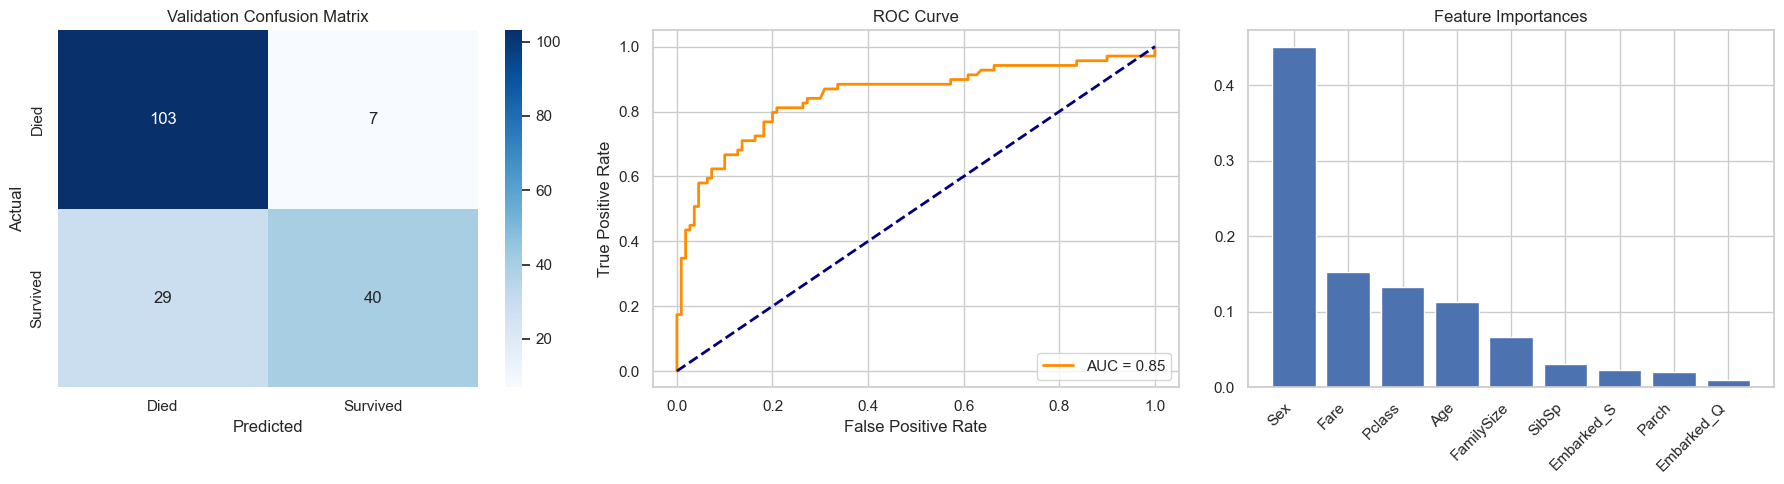

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Confusion Matrix
sns.heatmap(confusion_matrix(y_val, y_val_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Died', 'Survived'], yticklabels=['Died', 'Survived'], ax=axes[0])
axes[0].set_title('Validation Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_val, y_val_probs)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {auc:.2f}')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_title('ROC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc="lower right")

# Plot 3: Feature Importances
importances = model.feature_importances_
feature_names = X_train_full.columns
indices = np.argsort(importances)[::-1]
axes[2].bar(range(X_train_full.shape[1]), importances[indices], align="center")
axes[2].set_xticks(range(X_train_full.shape[1]))
axes[2].set_xticklabels([feature_names[i] for i in indices], rotation=45, ha='right')
axes[2].set_title('Feature Importances')

plt.tight_layout()
plt.show()

In [7]:
# Retrain on 100% of training data before generating final predictions
final_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
final_model.fit(X_train_full, y_train_full)

y_test_pred = final_model.predict(X_test_final)

print("\n=== Final Test Performance (vs gender_submission.csv) ===")
print(f"Test Accuracy: {accuracy_score(y_test_final, y_test_pred):.4f}")
print(f"Test F1-Score: {f1_score(y_test_final, y_test_pred):.4f}")

# Export submission CSV
submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Survived': y_test_pred
})
submission.to_csv('submission.csv', index=False)
print("\n'submission.csv' generated successfully!")


=== Final Test Performance (vs gender_submission.csv) ===
Test Accuracy: 0.9330
Test F1-Score: 0.9060

'submission.csv' generated successfully!
